# 소믈리에가 되어라! 성분표로 알아보는 와인 품질

이 프로젝트에서는 알코올 도수, 산도, 당도 같은 성분으로 레드 와인의 품질을 구분해 봤습니다. 와인마다 주어진 11개 성분을 모델에 입력하고, 품질 점수가 **7점 이상이면 우수**, 나머지는 일반으로 분류했습니다. 여기서 7점은 실습을 위해 정한 기준입니다.

이 노트북에서는 데이터를 정리하고, 모델을 비교하고, 틀린 사례를 살펴본 뒤 직접 값을 넣어 예측해 보겠습니다. 저장소 폴더에서 순서대로 실행해 주세요. 학습 셀을 실행하면 보고서와 모델 파일도 다시 만들어집니다.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from train import load_data, split_data, train
from predict import predict
from reporting import (FEATURE_LABELS, METRIC_LABELS, comparison_for_readers,
                       importance_for_readers, errors_for_readers)
import joblib

# 입력에 쓰는 영문 열 이름은 유지하고, 표를 보여 줄 때만 한국어 이름을 붙입니다.
X, y, audit = load_data()
audit_labels = {'raw_rows':'원본 기록 수', 'rows':'정리한 뒤 기록 수', 'duplicates_removed':'중복으로 정리한 기록 수', 'conflicting_rows_removed':'같은 입력에 정답이 달라 제외한 기록 수', 'missing_cells':'비어 있는 값의 수', 'positive_rate':'찾으려는 대상의 비율'}
display(pd.Series({label:audit[key] for key,label in audit_labels.items()}).to_frame('데이터 확인'))
display(X.head().rename(columns=FEATURE_LABELS))


,데이터 확인
원본 기록 수,1599.000000
정리한 뒤 기록 수,1359.000000
중복으로 정리한 기록 수,240.000000
같은 입력에 정답이 달라 제외한 기록 수,0.000000
비어 있는 값의 수,0.000000
찾으려는 대상의 비율,0.135394


,고정 산도,휘발성 산도,구연산,잔당,염화물,유리 이산화황,총 이산화황,밀도,pH,황산염,알코올 도수
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4


## 1. 자료를 나누고 분포를 살펴보겠습니다

먼저 같은 기록이 반복되어 있지 않은지 정리합니다. 그런 다음 학습 60%, 검증 20%, 테스트 20%로 나누겠습니다. 학습 자료는 모델을 만드는 데, 검증 자료는 모델과 판단 기준을 고르는 데, 테스트 자료는 마지막 성능 확인에 씁니다. 아래 분포표에서는 학습 자료만 살펴보겠습니다.

In [2]:
Xtr, Xv, Xt, ytr, yv, yt = split_data(X, y)
display(pd.DataFrame({'기록 수':[len(Xtr),len(Xv),len(Xt)],
                      '찾으려는 대상의 비율':[ytr.mean(),yv.mean(),yt.mean()]},
                     index=['학습','검증','테스트']))
statistics = Xtr.describe(include='all').T.rename(index=FEATURE_LABELS)
display(statistics.rename(columns={'count':'개수','mean':'평균','std':'표준편차',
    'min':'최솟값','25%':'하위 25%','50%':'중앙값','75%':'하위 75%','max':'최댓값',
    'unique':'서로 다른 값의 수','top':'가장 흔한 값','freq':'가장 흔한 값의 개수'}))

,기록 수,찾으려는 대상의 비율
학습,815,0.134969
검증,272,0.136029
테스트,272,0.136029


,개수,평균,표준편차,최솟값,하위 25%,중앙값,하위 75%,최댓값
고정 산도,815.0,8.351779,1.799978,4.60000,7.1000,7.90000,9.300000,15.90000
휘발성 산도,815.0,0.526000,0.185568,0.12000,0.3800,0.51000,0.630000,1.58000
구연산,815.0,0.278479,0.191378,0.00000,0.1050,0.26000,0.430000,0.79000
잔당,815.0,2.531043,1.322077,0.90000,1.9000,2.20000,2.600000,15.40000
염화물,815.0,0.087189,0.047498,0.01200,0.0705,0.07900,0.090000,0.61100
유리 이산화황,815.0,16.180982,10.470624,2.00000,8.0000,14.00000,21.000000,72.00000
총 이산화황,815.0,48.374233,34.673749,6.00000,23.0000,40.00000,64.000000,289.00000
밀도,815.0,0.996734,0.001830,0.99007,0.9957,0.99672,0.997825,1.00369
pH,815.0,3.307472,0.160239,2.86000,3.2100,3.31000,3.395000,4.01000
황산염,815.0,0.661460,0.178804,0.37000,0.5500,0.62000,0.730000,1.98000


## 2. 여러 모델을 같은 조건에서 학습해 보겠습니다

수치 범위를 맞추기 전후의 로지스틱 회귀와, 깊이를 달리한 의사결정나무를 비교하겠습니다.

우리가 찾는 대상이 적기 때문에 정확도만 보지는 않겠습니다. 검증 AP가 가장 높은 모델을 고르고, 그 모델의 검증 F1이 가장 높은 임계값을 찾겠습니다. 테스트 자료는 이 선택이 모두 끝난 다음에 확인합니다.

In [3]:
result = train()

학습과 평가를 마쳤습니다. 선택한 모델: 의사결정나무 · 깊이 5 / 임계값: 0.30
자세한 수치와 해석은 evaluation.md에서 확인할 수 있습니다.


,모델,학습 F1,검증 F1,검증 AP,테스트 정확도,테스트 F1
0,다수 클래스만 예측하는 기준 모델,0.000000,0.000000,0.136029,0.863971,0.000000
1,로지스틱 회귀 · 표준화 전,0.342105,0.352941,0.530158,0.875000,0.320000
2,로지스틱 회귀 · 표준화 후,0.409639,0.385965,0.479447,0.875000,0.392857
3,의사결정나무 · 깊이 3,0.431373,0.367347,0.533165,0.893382,0.431373
4,의사결정나무 · 깊이 5,0.633166,0.500000,0.534871,0.875000,0.468750
5,의사결정나무 · 깊이 8,0.633166,0.500000,0.500948,0.875000,0.468750
6,깊이 제한 없는 나무 · 비교용,1.000000,0.378378,0.227729,0.845588,0.487805


,임계값,정확도,정밀도,재현율,F1,ROC-AUC,AP
0,0.10,0.779412,0.358025,0.783784,0.491525,0.855952,0.534871
1,0.15,0.849265,0.465517,0.729730,0.568421,0.855952,0.534871
2,0.20,0.875000,0.529412,0.729730,0.613636,0.855952,0.534871
3,0.25,0.897059,0.604651,0.702703,0.650000,0.855952,0.534871
4,0.30,0.897059,0.604651,0.702703,0.650000,0.855952,0.534871
5,0.35,0.889706,0.652174,0.405405,0.500000,0.855952,0.534871
6,0.40,0.889706,0.652174,0.405405,0.500000,0.855952,0.534871
7,0.45,0.889706,0.652174,0.405405,0.500000,0.855952,0.534871
8,0.50,0.893382,0.700000,0.378378,0.491228,0.855952,0.534871
9,0.55,0.875000,0.636364,0.189189,0.291667,0.855952,0.534871


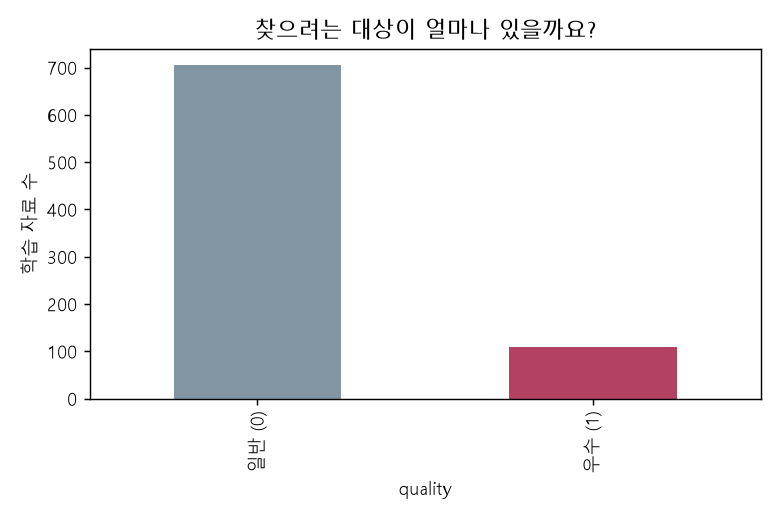

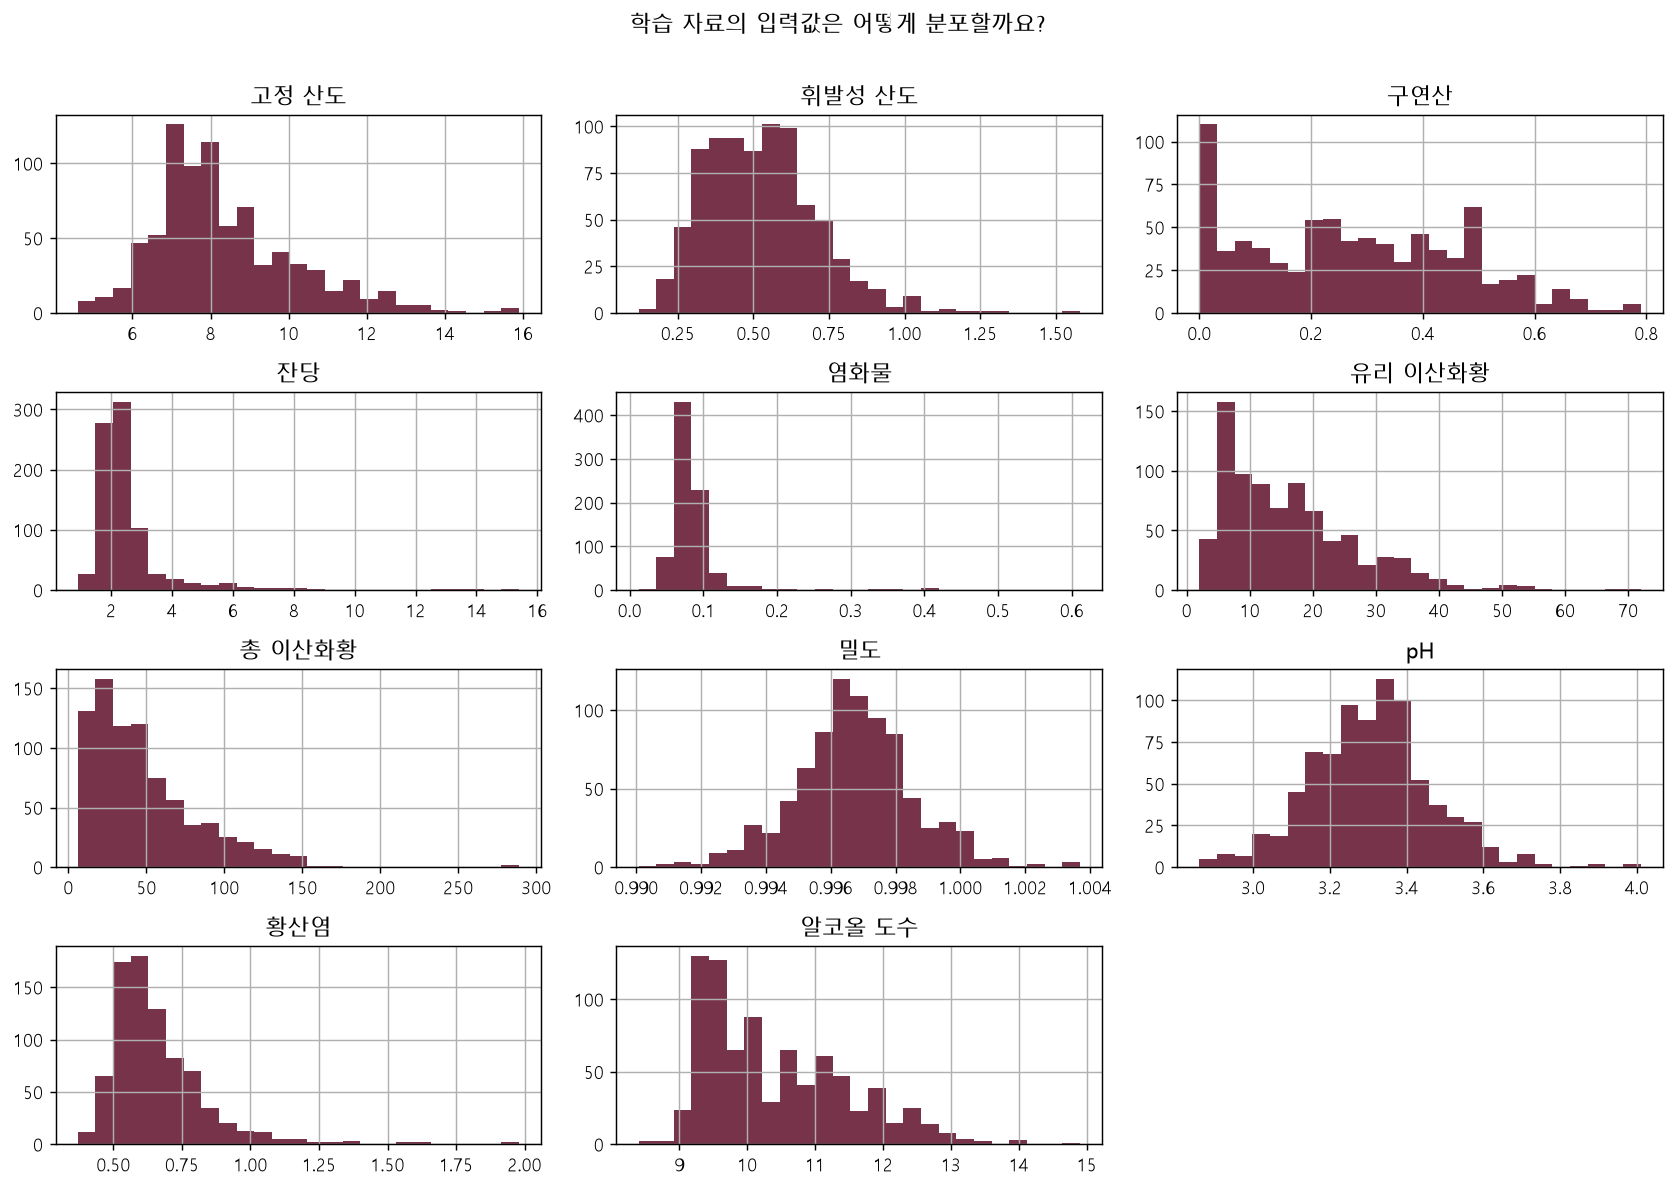

In [4]:
comparison = pd.read_csv('model_comparison.csv')
display(comparison_for_readers(comparison))
display(pd.read_csv('validation_thresholds.csv').rename(columns={**METRIC_LABELS, 'threshold':'임계값'}))
display(Image(filename='class_balance.png'))
display(Image(filename='feature_distributions.png'))

## 3. 맞힌 개수와 놓친 개수를 함께 보겠습니다

혼동 행렬에서 행은 실제 결과, 열은 모델의 예측입니다. 정밀도는 “대상이라고 예측한 것 중 얼마나 맞았는가”, 재현율은 “실제 대상 중 얼마나 찾아냈는가”를 보여 줍니다. 정확도가 높아도 찾고 싶은 대상을 많이 놓칠 수 있어서 함께 살펴보겠습니다.

틀린 사례도 표로 확인해 보겠습니다. 표의 확률은 별도로 보정한 값이 아닙니다.

,최종 테스트 결과
정확도,0.875000
정밀도,0.536585
재현율,0.594595
F1,0.564103
ROC-AUC,0.747729
AP,0.445303


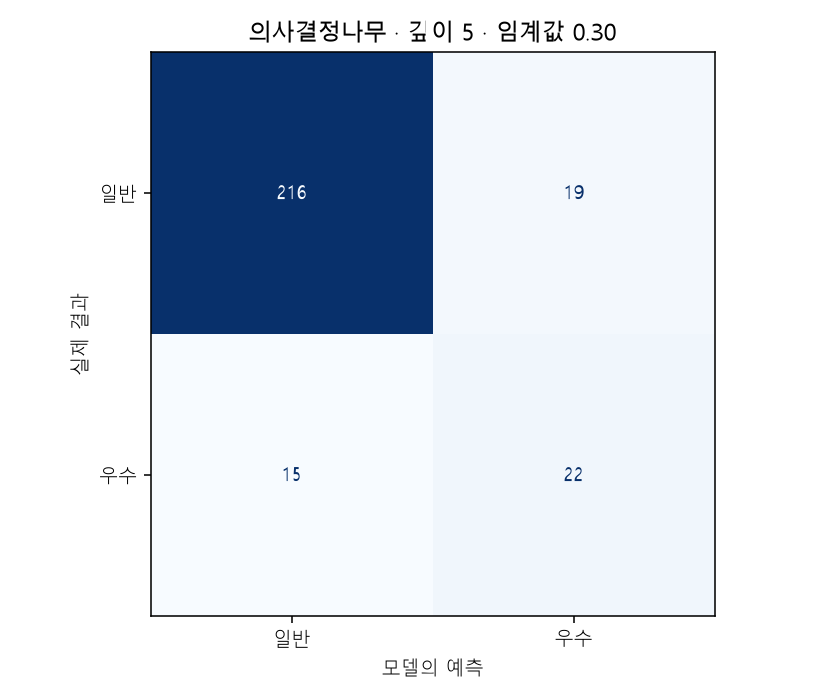

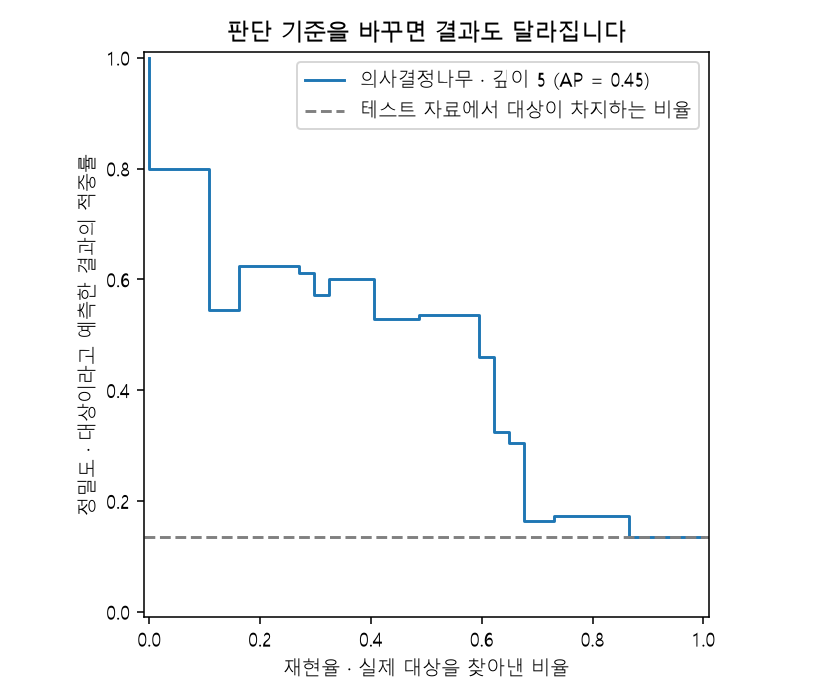

,원본 행 번호,실제 결과,예측 결과,우수일 확률,틀린 유형
0,288,우수,일반,0.000000,우수 와인을 놓침 (FN)
1,1086,우수,일반,0.000000,우수 와인을 놓침 (FN)
2,336,일반,우수,1.000000,잘못 추천 (FP)
3,1003,우수,일반,0.000000,우수 와인을 놓침 (FN)
4,1111,우수,일반,0.000000,우수 와인을 놓침 (FN)
5,1534,우수,일반,0.000000,우수 와인을 놓침 (FN)
6,209,우수,일반,0.019231,우수 와인을 놓침 (FN)
7,589,우수,일반,0.019231,우수 와인을 놓침 (FN)
8,200,우수,일반,0.019231,우수 와인을 놓침 (FN)
9,281,우수,일반,0.019231,우수 와인을 놓침 (FN)


In [5]:
display(pd.Series(result['test']).rename(index=METRIC_LABELS).to_frame('최종 테스트 결과'))
display(Image(filename='confusion_matrix.png'))
display(Image(filename='precision_recall.png'))
display(errors_for_readers(pd.read_csv('misclassified.csv').head(10), True))

## 4. 모델이 주로 참고한 항목을 찾아보겠습니다

검증 자료에서 입력 항목을 하나씩 무작위로 섞고 AP가 얼마나 떨어지는지 8번 확인했습니다. 많이 떨어질수록 모델이 그 항목에 의존했다는 뜻입니다. 다만 “중요한 항목을 바꾸면 결과도 좋아진다”는 인과관계까지 보여 주지는 않습니다.

,입력 항목,AP 감소량 평균,AP 감소량 표준편차
0,알코올 도수 (alcohol),0.271286,0.022251
1,황산염 (sulphates),0.187709,0.029228
2,pH (pH),0.065613,0.030856
3,휘발성 산도 (volatile acidity),0.039727,0.015217
4,유리 이산화황 (free sulfur dioxide),0.033227,0.027400
5,잔당 (residual sugar),0.014843,0.014304
6,고정 산도 (fixed acidity),0.004045,0.003536
7,염화물 (chlorides),0.001108,0.003568
8,총 이산화황 (total sulfur dioxide),-0.001782,0.006665
9,밀도 (density),-0.003473,0.003390


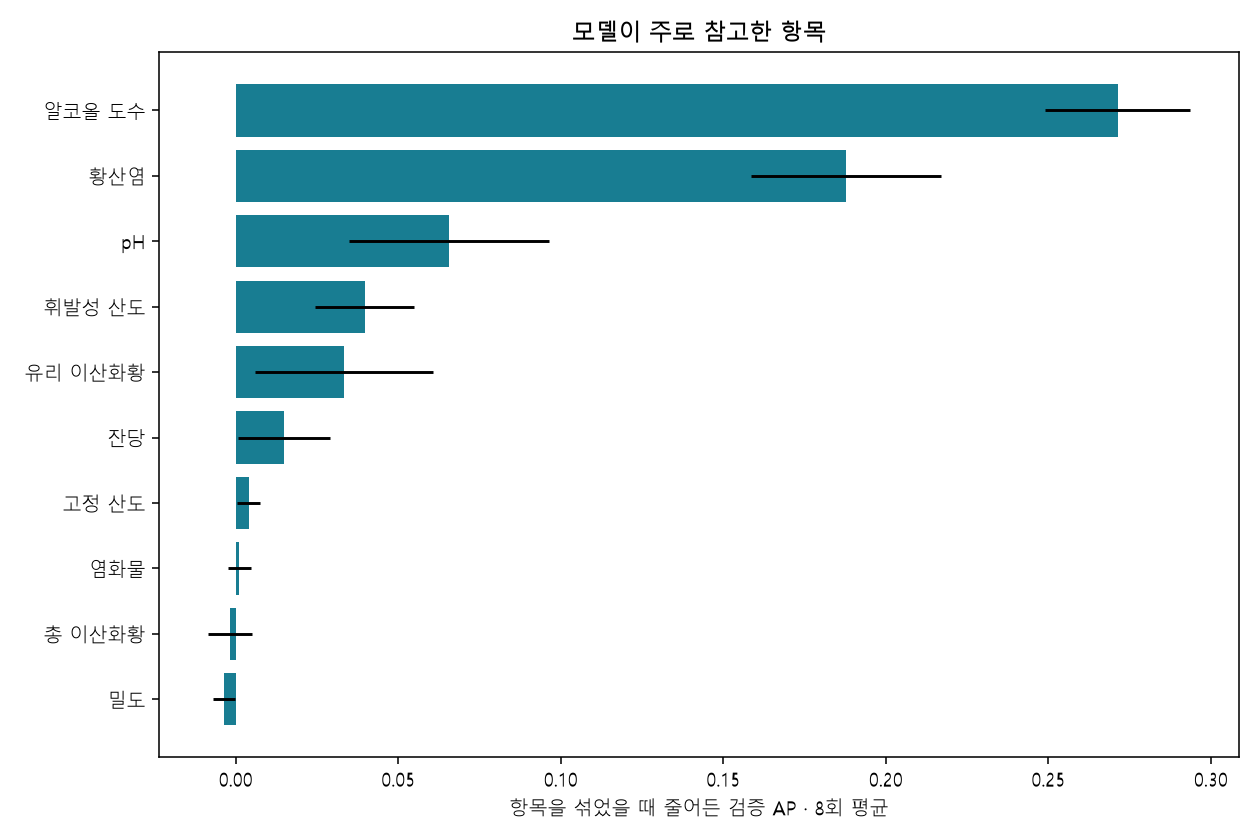

In [6]:
display(importance_for_readers(pd.read_csv('feature_importance.csv')))
display(Image(filename='feature_importance.png'))

## 5. 직접 값을 넣어 예측해 보겠습니다

`sample_input.json`의 값을 바꿔 다른 와인 성분도 시험해 보세요. 항목 이름은 그대로 두고 값만 바꾸면 됩니다. 어떤 열인지 헷갈리면 [입력 항목 안내](FEATURES.md)를 참고해 주세요. 학습 때 보지 못한 수치 범위가 나오면 결과에 해당 항목이 표시됩니다.

In [7]:
sample = json.loads(Path('sample_input.json').read_text(encoding='utf-8'))
bundle = joblib.load('model.joblib')
display(pd.Series(sample).rename(index=FEATURE_LABELS).to_frame('입력값'))
prediction = predict(sample, bundle)
display(pd.Series(prediction).rename(index={'label':'예측 결과','prediction':'예측 코드',
    'positive_probability':'우수 와인일 확률','threshold':'판단 기준(임계값)',
    'outside_training_range':'학습 범위를 벗어난 항목'}).to_frame('예측 확인'))

,입력값
고정 산도,6.90000
휘발성 산도,0.49000
구연산,0.19000
잔당,1.70000
염화물,0.07900
유리 이산화황,13.00000
총 이산화황,26.00000
밀도,0.99547
pH,3.38000
황산염,0.64000


,예측 확인
예측 결과,일반
예측 코드,0
우수 와인일 확률,0.034483
판단 기준(임계값),0.3
학습 범위를 벗어난 항목,[]


## 6. 결과를 문장으로 정리해 보겠습니다

마지막으로 성능 수치가 뜻하는 바와 이번 실험의 한계를 읽어 보겠습니다. 잘 맞힌 부분과 더 확인해야 할 부분을 함께 정리했습니다. 데이터 출처와 이용 조건은 [출처 안내](DATA_SOURCES.md)에 있습니다.

In [8]:
display(Markdown(Path("evaluation.md").read_text(encoding="utf-8")))

# 성분표로 읽어 본 와인 품질

와인을 직접 맛보지 않고도 성분표로 품질을 어느 정도 구분할 수 있는지 살펴봤습니다. 알코올 도수와 산도 등 11개 성분을 입력하고, 품질 점수가 **7점 이상이면 우수**, 그보다 낮으면 일반으로 나눴습니다. 7점은 이 실습에서 정한 기준입니다.

최종 모델은 **의사결정나무 · 깊이 5**였습니다. 한 번도 학습에 쓰지 않은 와인 272개 중 238개를 맞혀 정확도는 **87.50%**였습니다. 다만 우수 와인을 실제로 얼마나 찾아냈는지까지 보면, 재현율은 **59.46%**였습니다.

## 먼저 데이터를 정리했습니다

품종을 구분하는 `sklearn.datasets.load_wine` 대신 UCI의 레드 와인 품질 데이터를 사용했습니다. 원본은 1,599행이었습니다. 입력과 정답이 똑같이 반복된 240행을 정리한 뒤 1,359행으로 실험했습니다. 같은 기록이 학습과 테스트에 나눠 들어가 점수가 부풀려지는 일을 줄이기 위해서입니다. 같은 입력에 서로 다른 정답이 붙어 있는 사례는 중복 정리 후 발견되지 않았습니다.

비어 있는 값은 0개였고, 전체에서 우수 와인의 비율은 **13.54%**였습니다. 우리가 찾고 싶은 대상이 적다는 점을 염두에 두고 결과를 읽어야 합니다.

## 배울 자료와 시험 볼 자료를 나눴습니다

데이터는 학습 60%, 검증 20%, 테스트 20%로 나눴습니다. 학습 자료로 모델을 만들고, 검증 자료로 모델과 판단 기준을 골랐습니다. 테스트 자료는 이 선택이 모두 끝난 뒤 최종 성능을 확인하는 데만 썼습니다.

| 용도 | 기록 수 |
| --- | --- |
| 모델 학습 | 815 |
| 모델·임계값 선택을 위한 검증 | 272 |
| 최종 성능 확인 | 272 |

각 묶음의 정답 비율이 비슷하도록 층화 분할을 했고, `random_state=42`로 같은 분할을 다시 만들 수 있게 했습니다. 평균·표준편차나 결측값을 채울 기준은 **학습 자료에서만** 구했습니다. 데이터 분포를 그릴 때도 학습 자료만 사용했습니다. 이 과정을 `Pipeline`으로 묶어 테스트 정보가 학습에 섞이지 않게 했습니다.

## 여러 모델을 같은 조건에서 비교했습니다

아래 표는 모두 예측 확률 **0.50 이상**을 우수로 판단했을 때의 결과입니다. F1과 AP는 0~1 사이의 값이며, 클수록 좋습니다.

| 모델 | 학습 F1 | 검증 F1 | 검증 AP | 테스트 정확도 | 테스트 F1 |
| --- | --- | --- | --- | --- | --- |
| 다수 클래스만 예측하는 기준 모델 | 0.0000 | 0.0000 | 0.1360 | 0.8640 | 0.0000 |
| 로지스틱 회귀 · 표준화 전 | 0.3421 | 0.3529 | 0.5302 | 0.8750 | 0.3200 |
| 로지스틱 회귀 · 표준화 후 | 0.4096 | 0.3860 | 0.4794 | 0.8750 | 0.3929 |
| 의사결정나무 · 깊이 3 | 0.4314 | 0.3673 | 0.5332 | 0.8934 | 0.4314 |
| 의사결정나무 · 깊이 5 | 0.6332 | 0.5000 | 0.5349 | 0.8750 | 0.4688 |
| 의사결정나무 · 깊이 8 | 0.6332 | 0.5000 | 0.5009 | 0.8750 | 0.4688 |
| 깊이 제한 없는 나무 · 비교용 | 1.0000 | 0.3784 | 0.2277 | 0.8456 | 0.4878 |

### 수치 범위를 맞춘 이유

체류 시간이나 성분 농도처럼 입력마다 숫자 크기가 다르면 로지스틱 회귀의 학습과 규제에 영향을 줄 수 있습니다. `StandardScaler`는 학습 자료의 평균과 표준편차를 기준으로 이 범위를 맞춰 줍니다. 의사결정나무는 값을 기준으로 가지를 나누기 때문에 별도로 표준화하지 않았습니다.

로지스틱 회귀의 검증 F1은 표준화 전 0.3529, 표준화 후 0.3860였습니다. 다만 검증 AP는 0.5302에서 0.4794로 달라졌습니다. 이번처럼 지표에 따라 변화 방향이 다를 수 있으므로 표준화가 모든 점수를 높인다고 해석하면 안 됩니다.

이번 실험에서 수렴 경고는 나오지 않았습니다.

### 최종 모델과 판단 기준

일반 사례가 많은 데이터라 정확도만 보고 고르지 않았습니다. 검증 자료에서 **AP(Average Precision)**가 가장 높은 모델을 골랐습니다. AP는 우리가 찾는 대상을 예측 확률의 앞쪽에 얼마나 잘 모았는지 살펴보는 지표입니다. 여기서 쓴 AP는 PR 곡선의 넓이를 사다리꼴로 계산한 값과는 계산 방식이 다릅니다.

선택한 모델은 **의사결정나무 · 깊이 5**(`tree_depth_5`)입니다. 그다음 확률이 얼마 이상일 때 우수로 판단할지, 즉 **임계값**을 검증 자료에서 조정했습니다. 0.10부터 0.90까지 0.05 간격으로 비교해 F1이 가장 높은 **0.30**를 골랐습니다. 동률이면 더 큰 값을 사용했습니다.

깊이 제한 없는 나무는 과적합을 관찰하는 비교용으로만 사용했습니다. 또 검증 자료에서 특성 중요도를 평가하려고, 마지막에 학습·검증 자료를 합쳐 재학습하지는 않았습니다.

## 처음 보는 데이터에서는 이 정도로 맞혔습니다

다음은 선택한 모델에 조정한 임계값 **0.30**를 적용한 결과입니다. 앞의 비교 표는 0.50을 사용했으므로 수치가 다를 수 있습니다.

| 정확도 | 정밀도 | 재현율 | F1 | ROC-AUC | AP |
| --- | --- | --- | --- | --- | --- |
| 87.50% | 53.66% | 59.46% | 0.5641 | 0.7477 | 0.4453 |

모든 와인을 일반으로만 분류해도 정확도는 86.40%입니다. 일반 와인이 훨씬 많기 때문입니다. 그래서 87.50%라는 정확도와 함께 우수 와인에 대한 정밀도·재현율을 살펴봤습니다.

우수 와인 37개 가운데 22개를 찾았고, 15개는 놓쳤습니다. 일반 와인 235개 중에서는 19개를 우수하다고 잘못 추천했습니다.

**정밀도**는 “우수하다고 추천한 와인 중 실제로 맞은 비율”, **재현율**은 “실제 우수 와인 중 찾아낸 비율”입니다. 각각 TP/(TP+FP), TP/(TP+FN)으로 계산합니다.

![실제 결과와 예측 결과를 비교한 혼동 행렬](confusion_matrix.png)

행은 실제 결과, 열은 모델의 예측입니다. 일반을 0, 우수를 1로 두었을 때 TN=216, FP=19, FN=15, TP=22입니다.

![판단 기준에 따라 달라지는 정밀도와 재현율](precision_recall.png)

## 틀린 사례도 따로 살펴봤습니다

테스트에서 틀린 34건을 `misclassified.csv`에 모았습니다. 원본 행 번호와 입력값, 실제 결과, 예측 결과, 확률을 함께 볼 수 있습니다. 아래는 모델이 0.50에서 가장 멀리 떨어진 확률을 내놓고도 틀린 사례 5건입니다.

| 원본 행 번호 | 실제 결과 | 예측 결과 | 우수일 확률 | 틀린 유형 |
| --- | --- | --- | --- | --- |
| 288 | 우수 | 일반 | 0.0000 | 우수 와인을 놓침 (FN) |
| 1086 | 우수 | 일반 | 0.0000 | 우수 와인을 놓침 (FN) |
| 336 | 일반 | 우수 | 1.0000 | 잘못 추천 (FP) |
| 1003 | 우수 | 일반 | 0.0000 | 우수 와인을 놓침 (FN) |
| 1111 | 우수 | 일반 | 0.0000 | 우수 와인을 놓침 (FN) |

FP는 일반 와인을 우수하다고 잘못 추천한 경우, FN은 우수 와인을 놓친 경우입니다. 표의 확률은 별도로 보정하지 않은 값입니다. 특히 나무 모델의 0이나 1을 절대적인 확신으로 받아들이지는 않는 편이 좋겠습니다.

오답의 원인은 이 표만으로 단정하지 않았습니다. 테스트 오답을 보고 다음 모델을 개선한다면, 그 모델은 새 테스트 자료로 다시 확인해야 합니다.

## 학습 점수만 높으면 생기는 문제

깊이를 제한하지 않은 나무는 학습 F1이 **1.0000**였지만, 검증 F1은 **0.3784**였습니다. 배운 자료를 잘 외우더라도 새로운 자료에서는 잘 맞히지 못할 수 있다는 예입니다. 그래서 깊이를 3·5·8로 제한하고, 마지막 잎에 들어가는 학습 표본도 최소 10개가 되도록 해 비교했습니다.

## 모델이 주로 참고한 항목

입력 항목을 하나씩 무작위로 섞은 뒤 검증 AP가 얼마나 떨어지는지 8번씩 확인했습니다. 이를 **순열 중요도(permutation importance)**라고 합니다. 감소량이 크면, 이 모델이 그 항목에 많이 의존했다는 뜻입니다.

| 입력 항목 | AP 감소량 평균 | AP 감소량 표준편차 |
| --- | --- | --- |
| 알코올 도수 (alcohol) | 0.2713 | 0.0223 |
| 황산염 (sulphates) | 0.1877 | 0.0292 |
| pH (pH) | 0.0656 | 0.0309 |
| 휘발성 산도 (volatile acidity) | 0.0397 | 0.0152 |
| 유리 이산화황 (free sulfur dioxide) | 0.0332 | 0.0274 |

![입력 항목을 섞었을 때 성능이 얼마나 떨어졌는지 비교](feature_importance.png)

알코올 도수, 황산염, pH가 상위에 나타났습니다. 이 항목을 섞었을 때 모델 성능이 크게 떨어졌다는 뜻입니다. 다만 이 결과만으로 “도수를 높이면 품질이 좋아진다”거나 “황산염을 늘리면 된다”고 말할 수는 없습니다. 성분 사이의 관계와 관능 평가를 더 살펴봐야 합니다.

감소량이 음수인 항목은 이번 실험에서 중요도가 뚜렷하지 않을 수 있습니다. 서로 비슷한 정보를 담은 항목끼리는 중요도를 나눠 가질 수도 있습니다.

## 여기까지 확인했고, 다음에는 더 확인하고 싶습니다

이번 데이터는 포르투갈의 레드 Vinho Verde 와인입니다. 다른 산지나 화이트 와인에서도 같은 결과가 나오는지는 확인하지 않았습니다. 성분 분석을 바탕으로 한 보조 판단이므로 실제 시음 평가를 대신한다고 보기는 어렵습니다.

이번에는 한 번의 무작위 분할로 실험해서 분할을 바꾸면 점수가 얼마나 달라지는지, 신뢰구간은 어느 정도인지까지 계산하지 않았습니다. 다음에는 교차검증이나 반복 분할로 결과의 안정성을 확인하고, 예측 확률 보정과 오류 비용을 반영한 임계값 선택도 비교해 보고 싶습니다.

## 같은 결과를 다시 확인하려면

저장소에서 `python train.py`를 실행하면 학습과 보고서를 다시 만들 수 있습니다. 데이터 출처와 이용 조건은 [데이터 출처 안내](DATA_SOURCES.md)에 정리했습니다. 파일별로는 다음 기록을 남겼습니다.

- `split_manifest.csv`: 원본의 어느 행을 학습·검증·테스트에 썼는지
- `metrics.json`: 평가 수치, 실행 버전, 원본 파일의 SHA-256 확인값
- `requirements-lock.txt`: 실험 환경의 패키지 버전

CSV와 JSON의 영문 열 이름은 코드에서 그대로 읽을 수 있도록 유지했습니다. 이 보고서와 노트북에서는 한국어 이름을 덧붙여 설명했습니다.
